Part 1: Setup

In [ ]:
!pip install -q ultralytics

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


Part 2: Load a pretrained YOLO model

In [ ]:
model = YOLO("yolo11n.pt")
# What can this model detect?
print(f"Number of classes: {len(model.names)}")
print(model.names)

Number of classes: 80
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'ce

Part 3: Run detection on an image

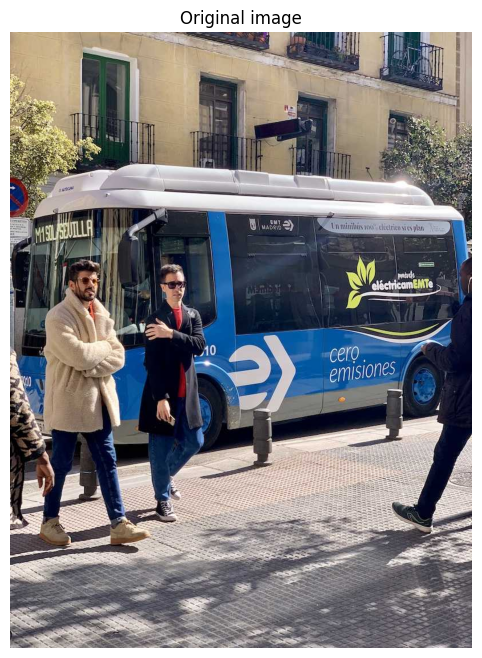

In [ ]:
!wget -q https://ultralytics.com/images/bus.jpg -O bus.jpg
plt.figure(figsize=(8, 8))
plt.imshow(Image.open("bus.jpg"))
plt.title("Original image")
plt.axis("off")
plt.show()


image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 405.6ms
Speed: 18.3ms preprocess, 405.6ms inference, 23.5ms postprocess per image at shape (1, 3, 640, 480)


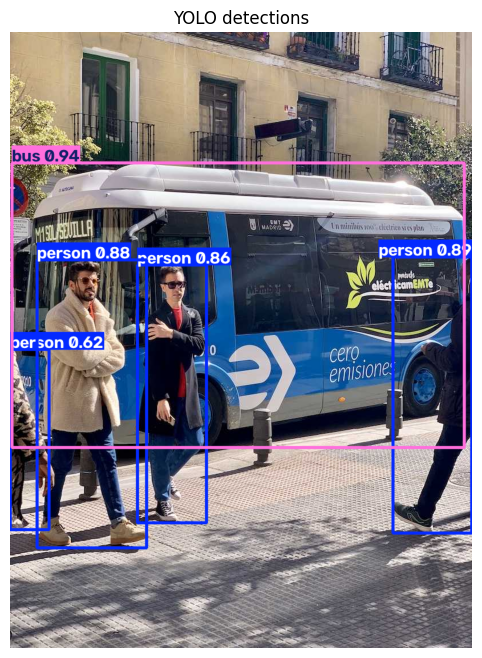

In [ ]:
results = model("bus.jpg")
result = results[0]
# result.plot() returns the annotated image as a BGR array, so [..., ::-1] flips it to RGB
plt.figure(figsize=(8, 8))
plt.imshow(result.plot()[..., ::-1])
plt.title("YOLO detections")
plt.axis("off")
plt.show()

Part 4: Look inside the results

In [ ]:
# Extract the bounding boxes from the detection results
boxes = result.boxes
print(f"Number of detections: {len(boxes)}\n")
# Iterate through each detected bounding box
for i, box in enumerate(boxes):
  # Extract the bounding box coordinates (x1, y1, x2, y2)
  # and convert the tensor values into a Python list
  x1, y1, x2, y2 = box.xyxy[0].tolist()
  # Extract the confidence score of the detection
  # and convert it into a standard Python float
  conf = float(box.conf[0])
  # Retrieve the class index and map it to its corresponding class label
  label = model.names[int(box.cls[0])]
  print(f"{i}: {label:10s} conf={conf:.2f} box=({x1:.0f}, {y1:.0f}, {x2:.0f},{y2:.0f})")

Number of detections: 5

0: bus        conf=0.94 box=(4, 229, 796,728)
1: person     conf=0.89 box=(671, 395, 810,879)
2: person     conf=0.88 box=(47, 400, 239,904)
3: person     conf=0.86 box=(223, 409, 344,860)
4: person     conf=0.62 box=(0, 556, 69,872)


Part 5: Try a different model


image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 675.2ms
Speed: 9.5ms preprocess, 675.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)


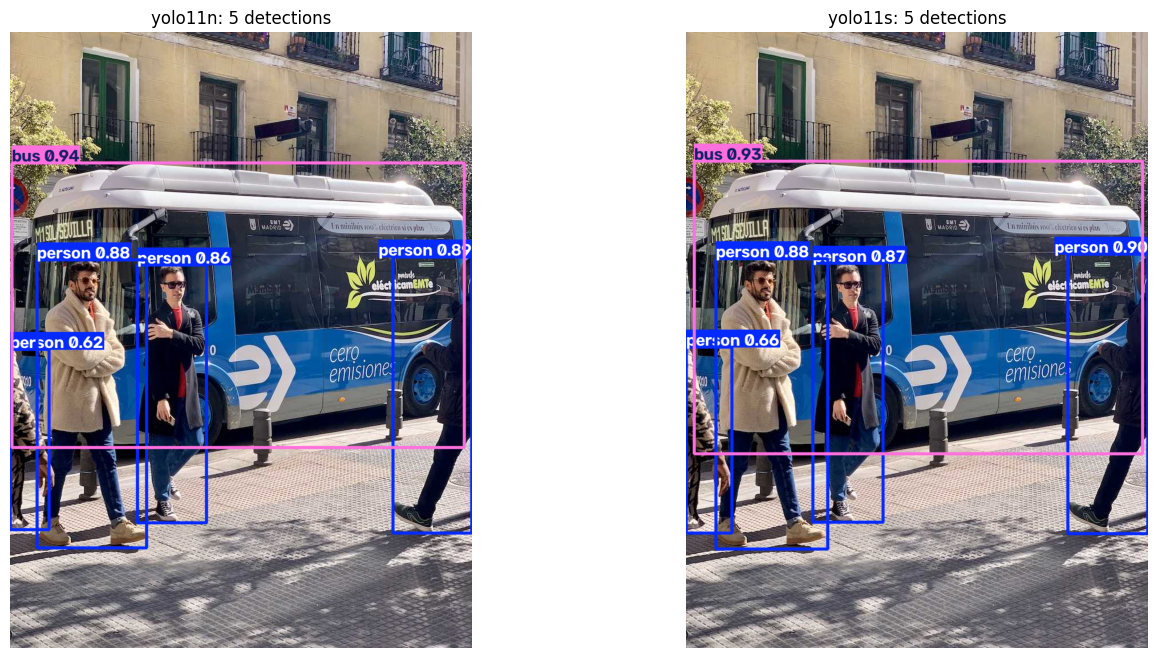

yolo11n speed: {'preprocess': 18.28438300003654, 'inference': 405.58822599996347, 'postprocess': 23.471183000026485}
yolo11s speed: {'preprocess': 9.498509999957605, 'inference': 675.2144270000144, 'postprocess': 1.4051189999690905}


In [ ]:
model_s = YOLO("yolo11s.pt") # try yolo11m.pt, yolov8n.pt, etc.
result_s = model_s("bus.jpg")[0]
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(result.plot()[..., ::-1])
axes[0].set_title(f"yolo11n: {len(result.boxes)} detections")
axes[1].imshow(result_s.plot()[..., ::-1])
axes[1].set_title(f"yolo11s: {len(result_s.boxes)} detections")
for ax in axes:
  ax.axis("off")
plt.show()
# YOLO also reports how long each step took (in milliseconds)
print("yolo11n speed:", result.speed)
print("yolo11s speed:", result_s.speed)

Part 6: Confidence threshold

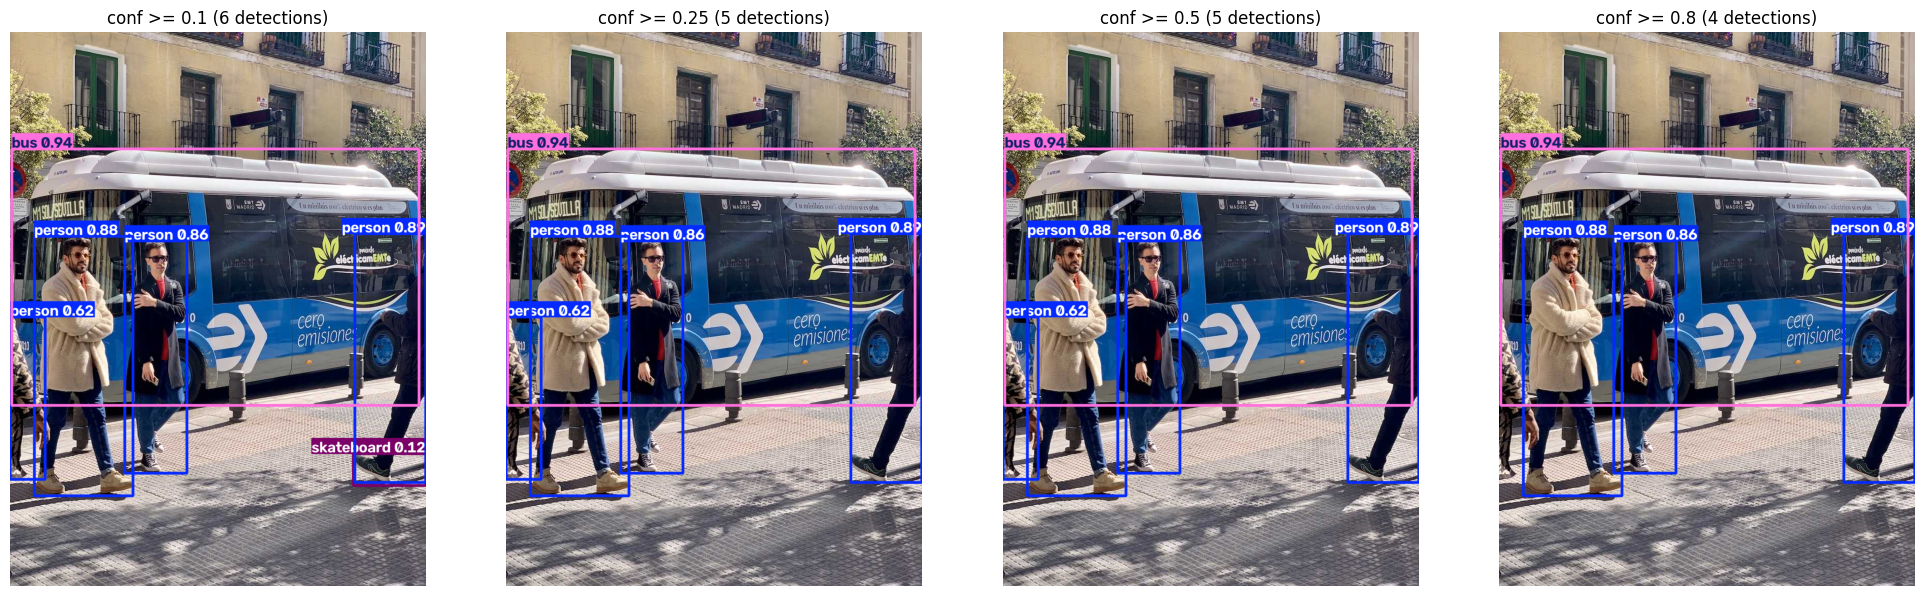

In [ ]:
thresholds = [0.1, 0.25, 0.5, 0.8]
fig, axes = plt.subplots(1, len(thresholds), figsize=(20, 6))
for ax, t in zip(axes, thresholds):
  r = model("bus.jpg", conf=t, verbose=False)[0]
  ax.imshow(r.plot()[..., ::-1])
  ax.set_title(f"conf >= {t} ({len(r.boxes)} detections)")

  ax.axis("off")
plt.tight_layout()
plt.show()

Part 7: Try your own image

In [ ]:
from google.colab import files
uploaded = files.upload()
my_image = list(uploaded.keys())[0]
print("Using:", my_image)

Saving cv3.png to cv3.png
Using: cv3.png



image 1/1 /content/cv3.png: 416x640 10 persons, 128.0ms
Speed: 2.4ms preprocess, 128.0ms inference, 0.8ms postprocess per image at shape (1, 3, 416, 640)


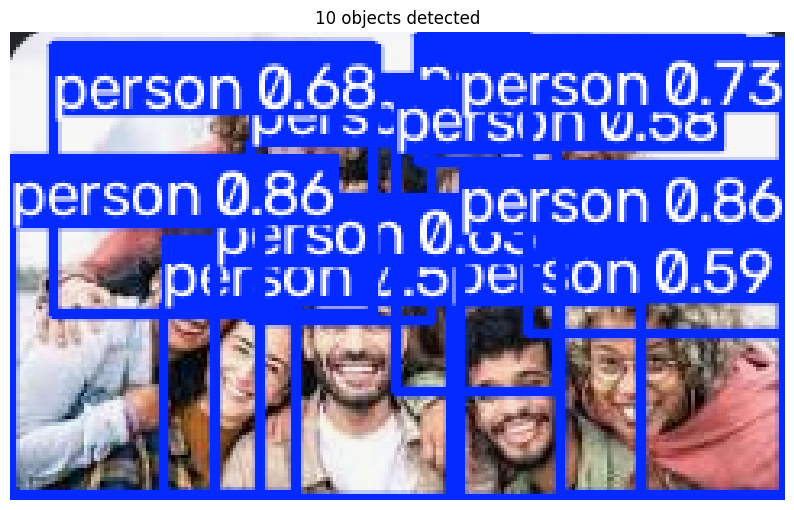

{'person': 10}


In [ ]:
from collections import Counter
r = model(my_image, conf=0.25)[0]
plt.figure(figsize=(10, 10))
plt.imshow(r.plot()[..., ::-1])
plt.title(f"{len(r.boxes)} objects detected")
plt.axis("off")
plt.show()
# Summary of what was found
counts = Counter(model.names[int(c)] for c in r.boxes.cls)
print(dict(counts))

Part 8: Detect only certain classes


image 1/1 /content/bus.jpg: 640x480 4 persons, 341.1ms
Speed: 17.8ms preprocess, 341.1ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)


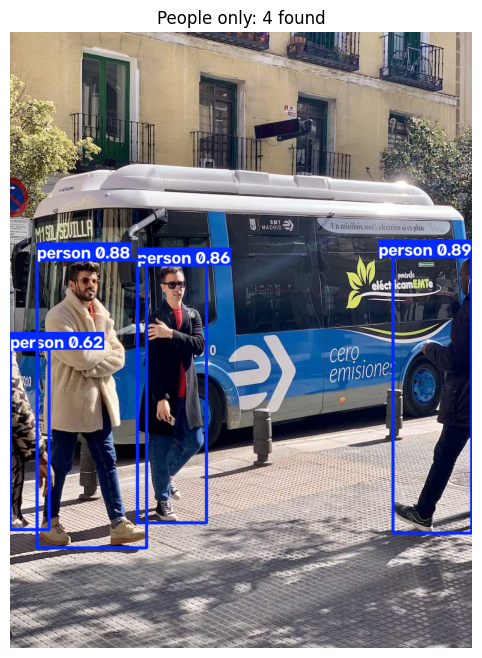

In [ ]:
# Run object detection on the image "bus.jpg"
# classes=[0] filters detections to class 0 (person) only
# [0] extracts the first result from the returned results list
r = model("bus.jpg", classes=[0])[0]
plt.figure(figsize=(8, 8))
plt.imshow(r.plot()[..., ::-1])
plt.title(f"People only: {len(r.boxes)} found")
plt.axis("off")
plt.show()

#lab task

info for selected dataset:
Clash of Clans Object Detection
- Creator: Find This Base
- Task: Object Detection
- Classes: 16
- Original dataset: 125 annotated images
- Version 4: 301 images
- Image size: 640 × 640
link: https://universe.roboflow.com/find-this-base/clash-of-clans-vop4y
choosen yolo model: YOLO11s (recomendeed by gpt)

Prepare the Clash of Clans dataset

In [ ]:
import zipfile
import os

zip_path = '/content/Clash of Clans.v5i.yolov8.zip'
extract_path = '/content/clash_of_clans_dataset'

# Create directory if it doesn't exist
os.makedirs(extract_path, exist_ok=True)

# Extract the zip file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Extracted all files to: {extract_path}")
print("Contents:", os.listdir(extract_path)[:5])

Load the pretrained YOLO11s model

In [ ]:
model = YOLO("yolo11s.pt")
# What can this model detect?
print(f"Number of classes: {len(model.names)}")
print(model.names)

Number of classes: 80
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'ce

Check your dataset folders

In [ ]:
for root, dirs, files in os.walk(extract_path):

    level = root.replace(extract_path, '').count(os.sep)

    indent = ' ' * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:

        print(f"{indent}    {file}")

clash_of_clans_dataset/
    README.dataset.txt
    data.yaml
    README.roboflow.txt
    valid/
        labels.cache
        images/
            IMG_1969_jpg.rf.fe3da293e0a294fd1f20e79401aa363c.jpg
            IMG_2034_jpg.rf.40ab3489487d018d0112f49622f0f9a0.jpg
            IMG_2025_jpg.rf.c4187b1ac22941ee379d55f2e7b43b84.jpg
            IMG_1881_jpg.rf.a87cce5cf026706851d181cfb066f681.jpg
            IMG_1931_jpg.rf.16f42f6d309c3de5661625af454aeb0c.jpg
        labels/
            IMG_2025_jpg.rf.c4187b1ac22941ee379d55f2e7b43b84.txt
            IMG_1980_jpg.rf.54e1778b82fbf613ab9c5f9e600478bd.txt
            IMG_1904_jpg.rf.4c9144add6097369a15cdc9a07445978.txt
            IMG_2014_jpg.rf.917d5e5e0ae8624b23016fe8f1e79725.txt
            IMG_1881_jpg.rf.a87cce5cf026706851d181cfb066f681.txt
    train/
        labels.cache
        images/
            IMG_1982_jpg.rf.e1bd3617bbc2b98bb8982a1c63c67775.jpg
            IMG_2022_jpg.rf.f9b3f502cd73f0c6ce5aef57ef22f474.jpg
            IMG_1863_JP

Find the data.yaml file then read.

In [ ]:
yaml_files = glob.glob(
    os.path.join(extract_path, "**", "data.yaml"),
    recursive=True
)

print("Found YAML files:", yaml_files)
data_yaml = yaml_files[0]

print("Dataset configuration file:", data_yaml)

Found YAML files: ['/content/clash_of_clans_dataset/data.yaml']
Dataset configuration file: /content/clash_of_clans_dataset/data.yaml


In [ ]:
with open(data_yaml, "r") as file:

    print(file.read())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 16
names: ['AD', 'AirSweeper', 'BombTower', 'Canon', 'ClanCastle', 'Eagle', 'Inferno', 'KingPad', 'Mortar', 'QueenPad', 'RcPad', 'Scattershot', 'TH13', 'WardenPad', 'WizzTower', 'Xbow']

roboflow:
  workspace: find-this-base
  project: clash-of-clans-vop4y
  version: 5
  license: CC BY 4.0
  url: https://universe.roboflow.com/find-this-base/clash-of-clans-vop4y/dataset/5


Train YOLO11s on the Clash of Clans dataset

In [ ]:
results = model.train(
    data=data_yaml,
    epochs=10,
    imgsz=640,
    batch=16,
    patience=10
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/clash_of_clans_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize

Display the training results

In [ ]:
from IPython.display import Image, display

display(Image(filename="runs/detect/train/results.png"))

Load the best trained weights

In [ ]:
best_model = YOLO("runs/detect/train/weights/best.pt")

print("Number of classes:", len(best_model.names))
print("Detected classes:", best_model.names)

Number of classes: 16
Detected classes: {0: 'AD', 1: 'AirSweeper', 2: 'BombTower', 3: 'Canon', 4: 'ClanCastle', 5: 'Eagle', 6: 'Inferno', 7: 'KingPad', 8: 'Mortar', 9: 'QueenPad', 10: 'RcPad', 11: 'Scattershot', 12: 'TH13', 13: 'WardenPad', 14: 'WizzTower', 15: 'Xbow'}


In [ ]:
metrics = best_model.val(data=data_yaml)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,418,992 parameters, 0 gradients, 21.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4920.8±1097.6 MB/s, size: 482.6 KB)
val: Scanning /content/clash_of_clans_dataset/valid/labels.cache... 24 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 24/24 1.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.4it/s 1.4s
                   all         24        959      0.935      0.912      0.967      0.767
                    AD         24         96      0.991          1      0.995      0.847
            AirSweeper         24         48      0.966      0.599      0.939      0.647
             BombTower         24         48      0.994          1      0.995      0.821
                 Canon         24        167      0.994      0.974      0.995      0.817
            ClanCastle         24

Print all four required metrics

In [ ]:
print("Precision:", metrics.box.mp)

print("Recall:", metrics.box.mr)

print("mAP50:", metrics.box.map50)

print("mAP50-95:", metrics.box.map)

Precision: 0.9347852362097311
Recall: 0.9116036949784125
mAP50: 0.9674796256030416
mAP50-95: 0.7667669674950313


Find the test images

In [ ]:
import glob
import os

test_images = glob.glob(
    os.path.join(extract_path, "**", "test", "images", "*"),
    recursive=True
)

print("Total test images:", len(test_images))

print("Available test images:")
print(test_images[:10])

Total test images: 13
Available test images:
['/content/clash_of_clans_dataset/test/images/IMG_2030_jpg.rf.a7af6f19d3560c91212ff3bc2c5210ca.jpg', '/content/clash_of_clans_dataset/test/images/IMG_1991_jpg.rf.cde0dcedc2ff8c2071dae2a1e41ca1cf.jpg', '/content/clash_of_clans_dataset/test/images/IMG_1976_jpg.rf.23c110c6b79b908b65562f75a09dcf70.jpg', '/content/clash_of_clans_dataset/test/images/IMG_1942_jpg.rf.6f2c969bed2ca1fd2a3f1ce8c5a8d379.jpg', '/content/clash_of_clans_dataset/test/images/IMG_2027_jpg.rf.77f401292885b32255205d12cd6823c7.jpg', '/content/clash_of_clans_dataset/test/images/20210117132140_jpg.rf.690e31b3fe12b17b7a60471c9f588040.jpg', '/content/clash_of_clans_dataset/test/images/20200920093240_jpg.rf.b4d439543f7d8ac9a1f665076da2a3ec.jpg', '/content/clash_of_clans_dataset/test/images/IMG_1946_jpg.rf.5a06337e2228f76949f54ab4076718e5.jpg', '/content/clash_of_clans_dataset/test/images/20210117131843_jpg.rf.e9493f815ce08c04728b2c212cc350bd.jpg', '/content/clash_of_clans_dataset/tes

Test the model on three Clash of Clans images

In [ ]:
if len(test_images) >= 3:

    selected_images = test_images[:3]

    print("Selected three test images:")

    for image in selected_images:
        print(image)

else:
    print("There are fewer than three test images.")

Selected three test images:
/content/clash_of_clans_dataset/test/images/IMG_2030_jpg.rf.a7af6f19d3560c91212ff3bc2c5210ca.jpg
/content/clash_of_clans_dataset/test/images/IMG_1991_jpg.rf.cde0dcedc2ff8c2071dae2a1e41ca1cf.jpg
/content/clash_of_clans_dataset/test/images/IMG_1976_jpg.rf.23c110c6b79b908b65562f75a09dcf70.jpg



image 1/1 /content/clash_of_clans_dataset/test/images/IMG_2030_jpg.rf.a7af6f19d3560c91212ff3bc2c5210ca.jpg: 640x640 4 ADs, 2 BombTowers, 7 Canons, 2 ClanCastles, 1 Eagle, 3 Infernos, 1 KingPad, 4 Mortars, 1 QueenPad, 1 RcPad, 2 Scattershots, 1 TH13, 5 WizzTowers, 4 Xbows, 31.3ms
Speed: 7.6ms preprocess, 31.3ms inference, 6.2ms postprocess per image at shape (1, 3, 640, 640)


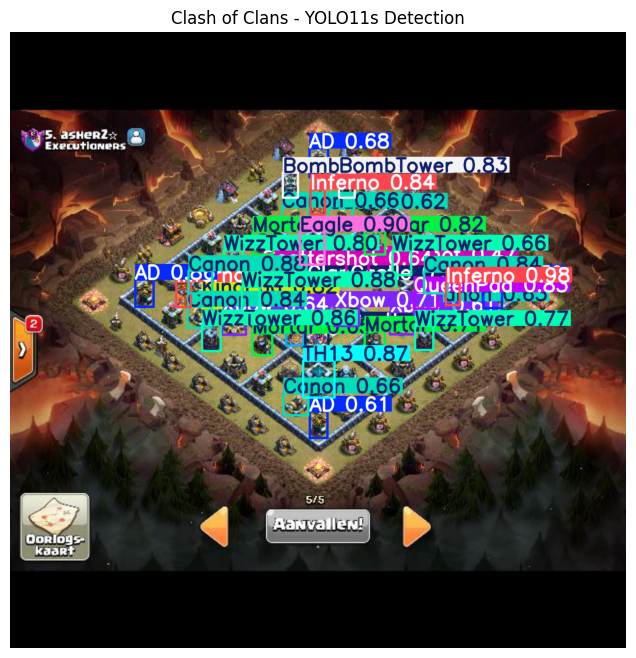


image 1/1 /content/clash_of_clans_dataset/test/images/IMG_1991_jpg.rf.cde0dcedc2ff8c2071dae2a1e41ca1cf.jpg: 640x640 4 ADs, 1 AirSweeper, 2 BombTowers, 7 Canons, 1 ClanCastle, 1 Eagle, 3 Infernos, 5 Mortars, 1 QueenPad, 2 RcPads, 2 Scattershots, 1 TH13, 1 WardenPad, 5 WizzTowers, 4 Xbows, 16.1ms
Speed: 4.0ms preprocess, 16.1ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)


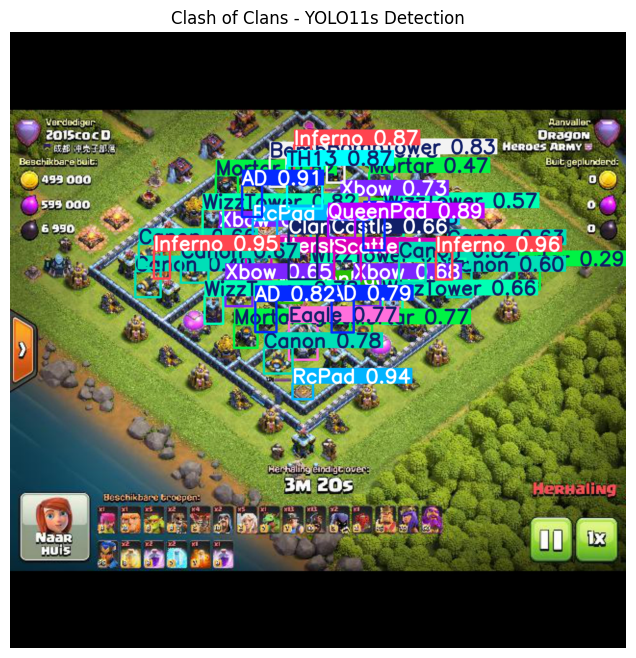


image 1/1 /content/clash_of_clans_dataset/test/images/IMG_1976_jpg.rf.23c110c6b79b908b65562f75a09dcf70.jpg: 640x640 4 ADs, 2 BombTowers, 7 Canons, 1 ClanCastle, 1 Eagle, 3 Infernos, 1 KingPad, 4 Mortars, 1 QueenPad, 1 RcPad, 2 Scattershots, 1 TH13, 5 WizzTowers, 4 Xbows, 17.5ms
Speed: 8.0ms preprocess, 17.5ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)


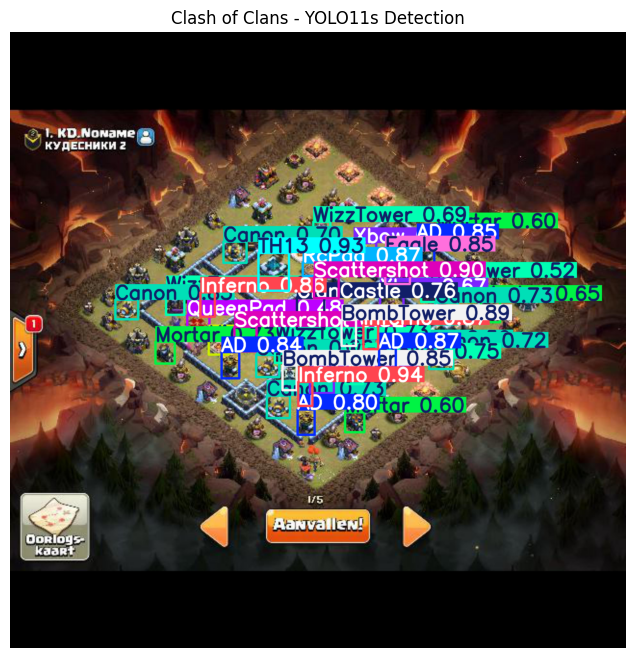

In [ ]:
import matplotlib.pyplot as plt

for image_path in selected_images:

    result = best_model(image_path)[0]

    plt.figure(figsize=(8, 8))

    plt.imshow(result.plot()[..., ::-1])

    plt.title("Clash of Clans - YOLO11s Detection")

    plt.axis("off")

    plt.show()

In [ ]:
for image_path in selected_images:

    result = best_model(image_path)[0]

    print("\nImage:", image_path)

    print("Number of detections:", len(result.boxes))

    for i, box in enumerate(result.boxes):

        label = best_model.names[int(box.cls[0])]

        confidence = float(box.conf[0])

        print(
            f"Object {i+1}: {label}, "
            f"Confidence: {confidence:.2f}"
        )


image 1/1 /content/clash_of_clans_dataset/test/images/IMG_2030_jpg.rf.a7af6f19d3560c91212ff3bc2c5210ca.jpg: 640x640 4 ADs, 2 BombTowers, 7 Canons, 2 ClanCastles, 1 Eagle, 3 Infernos, 1 KingPad, 4 Mortars, 1 QueenPad, 1 RcPad, 2 Scattershots, 1 TH13, 5 WizzTowers, 4 Xbows, 16.0ms
Speed: 2.7ms preprocess, 16.0ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

Image: /content/clash_of_clans_dataset/test/images/IMG_2030_jpg.rf.a7af6f19d3560c91212ff3bc2c5210ca.jpg
Number of detections: 38
Object 1: Inferno, Confidence: 0.98
Object 2: Eagle, Confidence: 0.90
Object 3: WizzTower, Confidence: 0.88
Object 4: Canon, Confidence: 0.88
Object 5: TH13, Confidence: 0.87
Object 6: AD, Confidence: 0.86
Object 7: WizzTower, Confidence: 0.86
Object 8: Inferno, Confidence: 0.85
Object 9: Canon, Confidence: 0.84
Object 10: Canon, Confidence: 0.84
Object 11: Inferno, Confidence: 0.84
Object 12: BombTower, Confidence: 0.83
Object 13: QueenPad, Confidence: 0.83
Object 14: KingPad, Confidenc

Let's start again from the beginning and make the process very simple. I will give you **one step at a time, with one code cell for each step**, and explain exactly what to do.

We are completing:

**Air University Computer Vision Lab Task 9**

- Dataset: Clash of Clans (Roboflow)
- Model: YOLO11s
- Task: Fine-tune the pretrained model, validate it, and detect objects in three test images.

You have already uploaded and extracted your ZIP file. We will include that step so you can understand the complete workflow.

# **Part 1 — Prepare your Google Colab notebook**

## **Step 1: Install YOLO and import libraries**

Create a new code cell and run:

```
!pip install -q ultralytics pyyaml
```

Now create another code cell:

```
import zipfileimport osimport globimport yamlimport matplotlib.pyplot as pltfrom ultralytics import YOLOfrom IPython.display import Image, display
```

**What are these libraries for?**

- `ultralytics`: Loads and trains YOLO11s.
- `zipfile`: Extracts your dataset ZIP file.
- `os`: Works with folders and files.
- `glob`: Finds images and dataset files.
- `yaml`: Reads the `data.yaml` configuration.
- `matplotlib`: Displays images and detection results.

## **Step 2: Extract the Clash of Clans dataset**

You have already done this step. This is your original code:

```
zip_path = '/content/Clash of Clans.v5i.yolov8.zip'extract_path = '/content/clash_of_clans_dataset'os.makedirs(extract_path, exist_ok=True)with zipfile.ZipFile(zip_path, 'r') as zip_ref:    zip_ref.extractall(extract_path)print("Extracted all files to:", extract_path)print("Contents:", os.listdir(extract_path)[:5])
```

**What happened?**

Your ZIP file was extracted into the folder:

`/content/clash_of_clans_dataset`

You do not need to extract it again if the files are already there.

# **Part 2 — Understand your dataset**

## **Step 3: Load the pretrained YOLO11s model**

You have already done this step too.

```
model = YOLO("yolo11s.pt")print("Number of classes:", len(model.names))print(model.names)
```

**Explanation:**

- `yolo11s.pt` loads the pretrained YOLO11 Small model.
- It originally knows 80 COCO classes.
- We will fine-tune it using Clash of Clans images so it learns your dataset's classes.

## **Step 4: Check your dataset folders**

Run this in a new cell:

```
for root, dirs, files in os.walk(extract_path):    level = root.replace(extract_path, '').count(os.sep)    indent = ' ' * 4 * level    print(f"{indent}{os.path.basename(root)}/")    for file in files[:5]:        print(f"{indent}    {file}")
```

**What are we checking?**

We want to find folders similar to these:

```
clash_of_clans_dataset/
│
├── train/
│   ├── images/
│   └── labels/
│
├── valid/
│   ├── images/
│   └── labels/
│
├── test/
│   ├── images/
│   └── labels/
│
└── data.yaml
```

- `train`: Images used for learning.
- `valid`: Images used for checking performance during training.
- `test`: Images used for final testing.
- `labels`: The correct object locations and class IDs.
- `data.yaml`: Information about image folders and object classes.

## **Step 5: Find the data.yaml file**

Run:

```
yaml_files = glob.glob(    os.path.join(extract_path, "**", "data.yaml"),    recursive=True)print("Found YAML files:", yaml_files)
```

Now set the path:

```
data_yaml = yaml_files[0]print("Dataset configuration file:", data_yaml)
```

This file tells YOLO where your images and labels are located.

## **Step 6: Read the data.yaml file**

Run:

```
with open(data_yaml, "r") as file:    print(file.read())
```

You should see something similar to:

```
train: ../train/images
val: ../valid/images
test: ../test/images

nc: ...
names:
  0: ...
  1: ...
```

The actual class names and number of classes will come from your Clash of Clans dataset.

**Important:** Do not change the class names. These are the object categories YOLO needs to learn.

# **Part 3 — Train YOLO11s**

## **Step 7: Train the model using your dataset**

This is the most important step in Lab Task 9.

You previously used 10 epochs. We will keep that same setting for now so that you do not have to change your previous training experiment.

Run:

```
results = model.train(    data=data_yaml,    epochs=10,    imgsz=640,    batch=16,    patience=10)
```

**Understand each setting:**

| Setting          | Meaning                                                   |
| ---------------- | --------------------------------------------------------- |
| `data=data_yaml` | Uses your Clash of Clans dataset                          |
| `epochs=10`      | Trains for up to 10 complete passes                       |
| `imgsz=640`      | Uses 640 × 640 images                                     |
| `batch=16`       | Processes 16 images per batch                             |
| `patience=10`    | Allows early stopping after 10 epochs without improvement |

**What happens now?**

1. YOLO loads its pretrained weights.
2. It reads your Clash of Clans training images.
3. It learns to recognize your dataset's objects.
4. It checks performance on validation images.
5. It saves the trained model.

You are now performing **fine-tuning**.

Your instructor allows you to adjust the number of epochs. Ten is suitable for an initial experiment; you can use 50 for a longer final training run if time and GPU resources allow.

## **Step 8: Display the training graph**

After training finishes, run:

```
display(    Image(filename="runs/detect/train/results.png"))
```

The graph shows how the model performed during training.

You may see:

- Training loss.
- Validation loss.
- Precision.
- Recall.
- mAP50.
- mAP50-95.

# **Part 4 — Load your trained model**

## **Step 9: Load the best trained weights**

Run:

```
best_model = YOLO("runs/detect/train/weights/best.pt")print("Number of classes:", len(best_model.names))print("Detected classes:", best_model.names)
```

**Why do we do this?**

There is an important difference:

| Model                                       | Meaning                                                 |
| ------------------------------------------- | ------------------------------------------------------- |
| `YOLO("yolo11s.pt")`                        | Original pretrained YOLO11s model                       |
| `YOLO("runs/detect/train/weights/best.pt")` | YOLO11s after learning from your Clash of Clans dataset |

We use `best.pt` for the remaining steps.

# **Part 5 — Validate your model**

## **Step 10: Run model.val()**

Your instructor specifically requires model validation.

Create a new code cell:

```
metrics = best_model.val(data=data_yaml)
```

**What does validation mean?**

It checks how well your trained model recognizes Clash of Clans objects in the validation images.

## **Step 11: Print the four required metrics**

Create another code cell:

```
print("Precision:", metrics.box.mp)print("Recall:", metrics.box.mr)print("mAP50:", metrics.box.map50)print("mAP50-95:", metrics.box.map)
```

These are the four values you must report in your lab.

| Metric    | Easy explanation                                              |
| --------- | ------------------------------------------------------------- |
| Precision | Out of the objects YOLO detected, how many were correct?      |
| Recall    | Out of all actual objects, how many did YOLO find?            |
| mAP50     | Detection performance at IoU 0.50                             |
| mAP50-95  | Detection performance across IoU thresholds from 0.50 to 0.95 |

**Save these four numbers.** You will need them in your lab report.

# **Part 6 — Test on three images**

## **Step 12: Find the test images**

Your instructor requires at least three images that were not used for training.

Run:

```
test_images = glob.glob(    os.path.join(        extract_path,        "**",        "test",        "images",        "*"    ),    recursive=True)print("Total test images:", len(test_images))print("Available test images:", test_images[:10])
```

This searches for images in the test folder.

## **Step 13: Select three test images**

Run:

```
selected_images = test_images[:3]print("Selected test images:")for image_path in selected_images:    print(image_path)
```

You should see three image paths.

If the total number of test images is zero, stop and show me your folder structure. We will correct the path.

## **Step 14: Detect Clash of Clans objects in the three images**

Run:

```
for image_path in selected_images:    result = best_model(image_path)[0]    plt.figure(figsize=(8, 8))    plt.imshow(result.plot()[..., ::-1])    plt.title("Clash of Clans - YOLO11s Detection")    plt.axis("off")    plt.show()
```

**What happens?**

For each image, YOLO11s:

1. Opens the image.
2. Detects Clash of Clans objects.
3. Draws bounding boxes around the detected objects.
4. Displays class names.
5. Displays confidence scores.

You will get three separate detection images.

## **Step 15: Print the objects detected in each image**

This is an additional step that helps you understand the output.

Run:

```
for image_path in selected_images:    result = best_model(image_path)[0]    print("\nImage:", image_path)    print("Number of detections:", len(result.boxes))    for i, box in enumerate(result.boxes):        label = best_model.names[int(box.cls[0])]        confidence = float(box.conf[0])        print(            f"Object {i+1}: {label}, "            f"Confidence: {confidence:.2f}"        )
```

This prints the object name and confidence score for every detected object.

# **Final checklist for your Lab Task 9**

## **Clash of Clans — YOLO11s**

**Your progress**

9/17

Install libraries and import modules

Extract Clash of Clans ZIP file

Load pretrained YOLO11s

Inspect dataset folders

Find data.yaml

Read data.yaml

Train YOLO11s

Display training graph

Load best.pt

Run model.val()

Print Precision

Print Recall

Print mAP50

Print mAP50-95

Find three test images

Display three images with bounding boxes

Print detected object details

**What I want you to do now:** Since you have already completed Steps 1–9 in your previous notebook, do not train again unnecessarily. Start with **Step 10 (validation)** in your existing Colab notebook. Run it, then Step 11, and share the four metric values with me. I will explain your actual model performance in simple words.